# Groupby Operations: Applying Aggregations to Groups of Data

## Setup

### Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Concatenation / Appends

The `pd.concat()` function and `DataFrame.append()` method take DataFrames with identical columns and make a DataFrame that is **taller** than either of them by stacking them on top of each other.

For example, it can turn this `df1` DataFrame:

| Day | Weather |
| :-: | :---:   |
| Monday | Sunny   |
| Tuesday | Rainy |

and this `df2` DataFrame:

| Day | Weather |
| :-: | :---:   |
| Wednesday | Sunny   |
| Thursday | Rainy |

into this:

| Day | Weather |
| :-: | :---:   |
| Monday | Sunny   |
| Tuesday | Rainy |
| Wednesday | Sunny   |
| Thursday | Rainy |

with one line of code:

```python
pd.concat([df1, df2])
```

**Note:** If you'd like pandas to ignore the index of the dataframes when appending them, the following option is helpful:

```python
pd.concat([df1, df2], ignore_index=True)
```

**Note:** With the `pd.concat()` function, you can concatenate as many dataframes in one step as you want!

| Code | Description |
|---|---|
| `pd.concat([df1, df2])` | Concatenate DataFrames vertically (stack them on top of each other). |
| `pd.concat([df1, df2], ignore_index=True)` | Concatenate DataFrames and reset the index to 0, 1, 2, ... |
| `pd.concat([df1, df2, df3])` | Concatenate multiple DataFrames in a single operation. |

Run the cells below to create three DataFrames that we'll use to practice concatenating DataFrames with the `pd.concat` function.

#### **Exercises**

**Exercise**: Concatenate df1 and df2 together!

Run to get `df1`:

In [27]:
df1 = pd.DataFrame({'Name': ['Jackson', 'Josh', 'Jenny'], 'Age': [16, 19, 17]})
df1

,Name,Age
0,Jackson,16
1,Josh,19
2,Jenny,17


Run to get `df2`:

In [26]:
df2 = pd.DataFrame({'Name': ['Jess', 'Jon', 'Joe'], 'Age': [21, 16, 23]}, index=[3, 4, 5])
df2

,Name,Age
3,Jess,21
4,Jon,16
5,Joe,23


In [22]:
pd.concat([df1, df2])

,Name,Age
0,Jackson,16
1,Josh,19
2,Jenny,17
3,Jess,21
4,Jon,16
5,Joe,23


**Exercise**: Concatenate df2 and df3 together!

Run to get `df2` ((notice it has "Name", then "Height", then "Age"):

In [32]:
df2 = pd.DataFrame({'Name': ['Jess', 'Jon', 'Joe'], 'Height': [168, 162, 165], 'Age': [21, 16, 23]}, index=[3, 4, 5])
df2

,Name,Height,Age
3,Jess,168,21
4,Jon,162,16
5,Joe,165,23


Run to get `df3` (notice it has "Age", then "Name", then "Height"):

In [34]:
df3 = pd.DataFrame({'Age': [5, 10, 61], 'Name': ['Jill', 'Josephine', 'Jack'], 'Height': [180, 185, 190]})
df3

,Age,Name,Height
0,5,Jill,180
1,10,Josephine,185
2,61,Jack,190


Use `pd.concat()` to concatenate the rows of the `df2` and `df3`, and check that it was done properly.

In [35]:
pd.concat([df2, df3])

,Name,Height,Age
3,Jess,168,21
4,Jon,162,16
5,Joe,165,23
0,Jill,180,5
1,Josephine,185,10
2,Jack,190,61


**Exercise**: Using all of `df1`, `df2`, and `df3`, concatenate all three dataframes together into one dataframe (just `df`).  Can you do it in a single line of code?  And what happens when some data is missing?  Also, try adding "ignore_index" to relable the row numbers properly: `pd.concat(..., ignore_index=True)`.

In [36]:
df1 = pd.DataFrame({'Name': ['Jackson', 'Josh', 'Jenny'], 'Age': [16, 19, 17]})
df2 = pd.DataFrame({'Name': ['Jess', 'Jon', 'Joe'], 'Height': [168, 162, 165], 'Age': [21, 16, 23]}, index=[3, 4, 5])
df3 = pd.DataFrame({'Age': [5, 10, 61], 'Name': ['Jill', 'Josephine', 'Jack'], 'Height': [180, 185, 190]})

In [40]:
pd.concat([df1, df2, df3], ignore_index=True)

,Name,Age,Height
0,Jackson,16,NaN
1,Josh,19,NaN
2,Jenny,17,NaN
3,Jess,21,168.0
4,Jon,16,162.0
5,Joe,23,165.0
6,Jill,5,180.0
7,Josephine,10,185.0
8,Jack,61,190.0


**Exercise**: What if your dataframes are stored in seperate files?  How to load them all into one giant dataframe? Run each of the following to see some code snippets for how you might do it:

The **"One at a time" method**: The following is the most complicated, but the most descriptive: it reads each one dataframe one at a time, adds it to a list, and then concatenates everything together:

In [18]:
dfs = []
for file in ['data/df1.csv', 'data/df2.csv']:
    df = pd.read_csv(file)
    dfs.append(df)

df_all = pd.concat(dfs).reset_index(drop=True)
df_all

,Name,Age,Height
0,Jackson,16,NaN
1,Josh,19,NaN
2,Jenny,17,NaN
3,Jess,21,168.0
4,Jon,16,162.0
5,Joe,23,165.0


The **"Let [Dask DataFrame](https://docs.dask.org/en/stable/dataframe.html) Handle the Multi-File Management for Me" Method**: Dask-Dataframe makes it easier to work lots of dataframes and files all at once, and calling "compute()" outputs a Pandas Dataframe.  Good for handling large amounts of data, and for not having to do complex loops in analysis code.

In [22]:
import dask.dataframe as dd

df_all = dd.read_csv('data/df*.csv').compute().reset_index(drop=True)
df_all

,Name,Age,Height
0,Jackson,16,NaN
1,Josh,19,NaN
2,Jenny,17,NaN
3,Jess,21,168.0
4,Jon,16,162.0
5,Joe,23,165.0


The **"Pretend I'm Working With an SQL Database using [DuckDB](https://duckdb.org/docs/2.0/clients/python/overview)" Method"**:  SQL databases are basically a bunch of tables, and so are Dataframes.  Sometimes useful to know!

In [23]:
import duckdb

df_all = duckdb.sql('SELECT * FROM read_csv("data/df*.csv")').df()
df_all

,Name,Age
0,Jackson,16
1,Josh,19
2,Jenny,17
3,Jess,21
4,Jon,16
5,Joe,23


## Get Summary Statistics for Different Subgroups in Titanic Dataset Using Groupby

Usually, you don't just want to get a single metric from a dataset--you want to compare that metric between different subgroups of your data. For example, you want the mean **monthly** temperature, or the maximum firing rate of **each neuron**, or the total income of **each country**, and so on.

The **groupby()** method lets you specify that an operation will be done on each *same-valued* row for a given column.  For example, to ask for the mean temperature by month:

```python
>>> df.groupby('month').temperature.mean()
```

To get the maximum firing rate of each neuron:

```python
>>> df.groupby('neuron_id').firing_rate.max()
```

You can also group by as many columns as you like, getting as many groups as unique combinations between the columns:

```python
>>> df.groupby(['year', 'month']).temperature.mean()
```

Groupby objects are **lazy**, meaning they don't start calculating anything until they know the full pipeline.  This approach is called the **"Split-Apply-Combine"** workflow.  You can get more info on it here: https://pandas.pydata.org/pandas-docs/stable/user_guide/groupby.html

Let's try this out on the Titanic Dataset!

| Code | Description |
|---|---|
| `df.head()` | Display the first 5 rows of a DataFrame. |
| `df.groupby('column')['column2'].mean()` | Group a DataFrame by `column` and calculate the mean of `column2` for each group. |
| `df.groupby('column')['column2'].median()` | Group a DataFrame by `column` and calculate the median of `column2` for each group. |
| `df.groupby(['col1', 'col2'])['col3'].mean()` | Group a DataFrame by multiple columns `col1` and `col2` and calculate the mean. |
| `df[['col1', 'col2']]` | Select multiple columns from a DataFrame. |
| `df.value_counts()` | Count unique combinations of values in a DataFrame. |


#### **Exercises**

**Exercise**: Load all the titanic data in the `data/` folder into a variable called `df`:

In [30]:
import dask.dataframe as dd
df = dd.read_csv('data/titanic_*.csv').compute().reset_index(drop=True)
df

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
1,1,2,female,14.0,1,0,30.0708,C,Second,child,False,<NA>,Cherbourg,yes,False
2,1,3,female,NaN,0,0,7.2250,C,Third,woman,False,<NA>,Cherbourg,yes,True
3,0,3,male,NaN,0,0,7.2250,C,Third,man,True,<NA>,Cherbourg,no,True
4,0,1,male,40.0,0,0,27.7208,C,First,man,True,<NA>,Cherbourg,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884,0,2,male,28.0,0,0,10.5000,S,Second,man,True,<NA>,Southampton,no,True
885,0,3,male,25.0,0,0,7.0500,S,Third,man,True,<NA>,Southampton,no,True
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,<NA>,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True


**Example**: What was the mean age, grouped by class?

In [31]:
df.groupby('class').age.mean()

class
First     38.105543
Second    29.877630
Third     25.140620
Name: age, dtype: float64

**Exercise**: What was the median ticket fare for each class?

In [32]:
df.groupby('class')['fare'].median()

class
First     58.6896
Second    14.2500
Third      8.0500
Name: fare, dtype: float64

**Exercise**: What was the survival rate for each class?

In [ ]:
df.groupby('class')['survived'].mean()

class
First     0.629630
Second    0.472826
Third     0.242363
Name: survived, dtype: float64

**Exercise**: What was the survival rate for each sex?

In [33]:
df.groupby('sex')['survived'].mean()

sex
female    0.740385
male      0.188908
Name: survived, dtype: float64

**Exercise**: What was the survival rate, broken down by both sex and class?

In [34]:
df.groupby(['class', 'sex'])['survived'].mean()

class   sex   
First   female    0.967391
        male      0.368852
Second  female    0.921053
        male      0.157407
Third   female    0.500000
        male      0.135447
Name: survived, dtype: float64

**Exercise**: Which class tended to travel alone more often?  Did it matter where they were embarking from?

In [35]:
df.groupby(['embark_town', 'class'])['alone'].mean()

embark_town  class 
Cherbourg    First     0.482353
             Second    0.352941
             Third     0.575758
Queenstown   First     0.000000
             Second    1.000000
             Third     0.750000
Southampton  First     0.519685
             Second    0.579268
             Third     0.657224
Name: alone, dtype: float64

**Exercise**: What was the median ticket fare for each embarking town?

In [ ]:
df.groupby('embark_town').fare.median()

embark_town
Cherbourg      29.70
Queenstown      7.75
Southampton    13.00
Name: fare, dtype: float64

**Exercise**: What was the median age of the survivors vs non-survivors, when sex is considered as a factor?

In [ ]:
df.groupby(['survived', 'sex']).age.median()

survived  sex   
0         female    24.5
          male      29.0
1         female    28.0
          male      28.0
Name: age, dtype: float64

#### Mini-Demo:

In [ ]:
df.groupby(['sex'])[['survived', 'age']].mean()

,survived,age
sex,,
female,0.742038,27.915709
male,0.188908,30.726645


## Plotting with Seaborn

Seaborn is a data visualization library that uses Pandas Dataframes to produce statistical plots; in other words, it takes Dataframes and does Groupby automatically for you

(https://seaborn.pydata.org/examples/index.html)

Most of its functions have a similar interface:

```python
import seaborn as sns
sns.catplot(data=df, x="ColName", y="ColName", hue="ColName", row="ColName", col="ColName", kind="bar")
# kind can be "point", "bar", "violin", "box", "boxen", "count", "strip", "swarm"
```

| Code | Description |
| :-- | :-- |
| `df.sort_index()` | Sort a DataFrame by its index. |
| `df.unstack()` | Pivot the innermost level of index to columns. |
| `sns.catplot(data=df, x='col', y='col')` | Create a categorical plot using Seaborn. |
| `sns.catplot(data=df, x='col', y='col', kind='bar')` | Specify the plot type. Options: `"point"`, `"bar"`, `"violin"`, `"box"`, `"boxen"`, `"count"`, `"strip"`, `"swarm"`. |
| `sns.catplot(data=df, x='col', y='col', order=[...])` | Specify the order of categories on the x-axis. |
| `sns.catplot(data=df, x='col', y='col', hue='col')` | Add a categorical variable to create grouped plots with different colors. |
| `sns.catplot(data=df, x='col', y='col', col='col')` | Create separate subplot columns for each category. |
| `sns.catplot(data=df, x='col', y='col', row='col')` | Create separate subplot rows for each category. |

Instead of making text tables, let's try out seaborn's **catplot** function to make plots that compare one or more "categorical" variables to a "quantitative" variable.  

#### **Exercises**

**Example**: What was the average age of the people in each class?

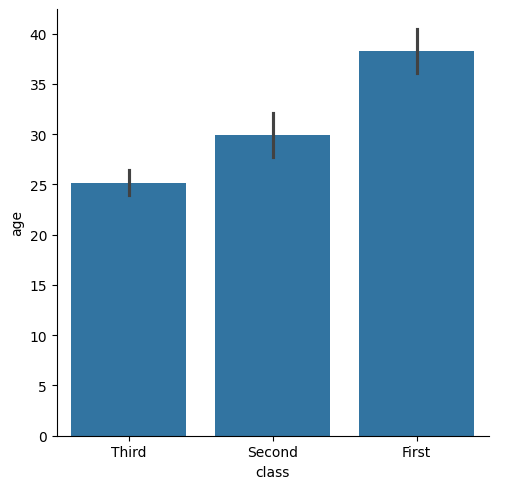

In [ ]:
class_order = ['Third', 'Second', 'First']
sns.catplot(data=df, x="class", y='age', order=class_order, kind='bar');  # kind= can be "point", "bar", "violin", "box", "boxen", "count", "strip", "swarm"

**Exercise**: What was the average ticket fare for each class?

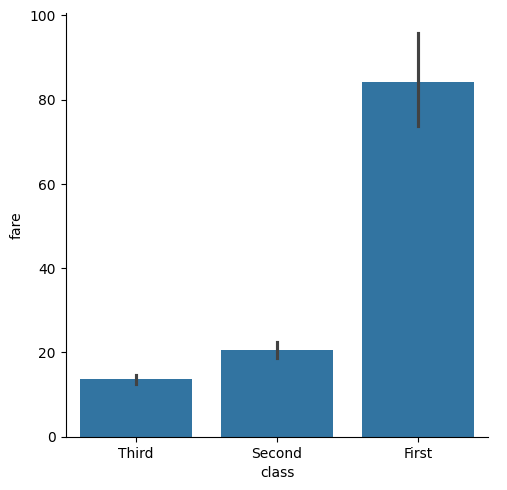

In [ ]:
sns.catplot(data=df, x='class', y='fare', order=class_order, kind='bar');

**Exercise**: What was the average survival rate for each class?

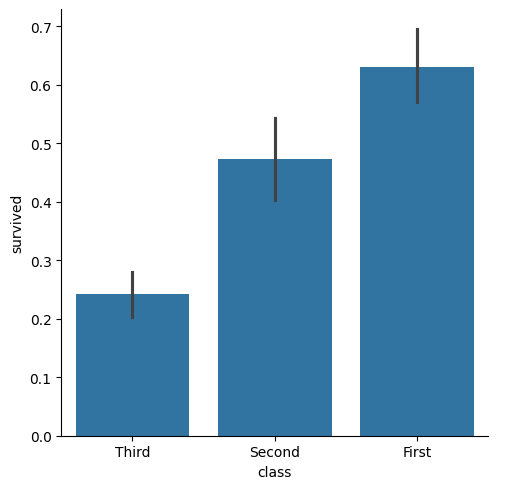

In [ ]:
sns.catplot(data=df, x='class', order=class_order, y='survived', kind='bar');

**Exercise**: What was the survival rate, broken down by both sex and class? **Hint**: `hue=`, `row=`, `col=`

In [ ]:
df[['class', 'survived', 'sex']].value_counts().sort_index().unstack()

sex 
 female 
 male 
 
 
 class 
 survived 
 
 
 
 
 
 
 First 
 0 
 3 
 77 
 
 
 1 
 91 
 45 
 
 
 Second 
 0 
 6 
 91 
 
 
 1 
 70 
 17 
 
 
 Third 
 0 
 72 
 300 
 
 
 1 
 72 
 47

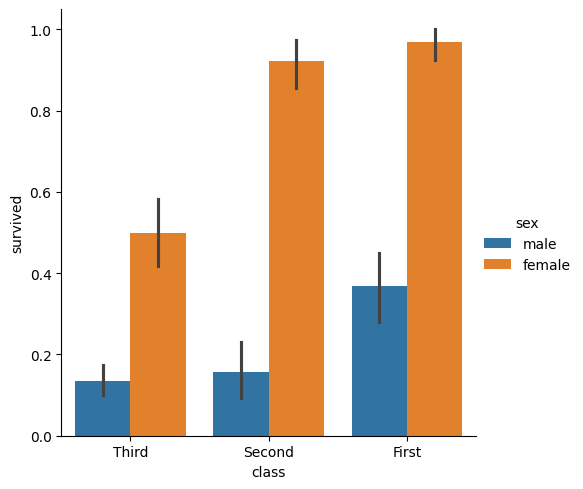

In [ ]:
sns.catplot(data=df, x='class', y='survived', order=class_order, hue='sex', kind='bar');

**Exercise**: Which class tended to travel alone more often?  Did it matter where they were embarking from?  What if sex was also factored in?

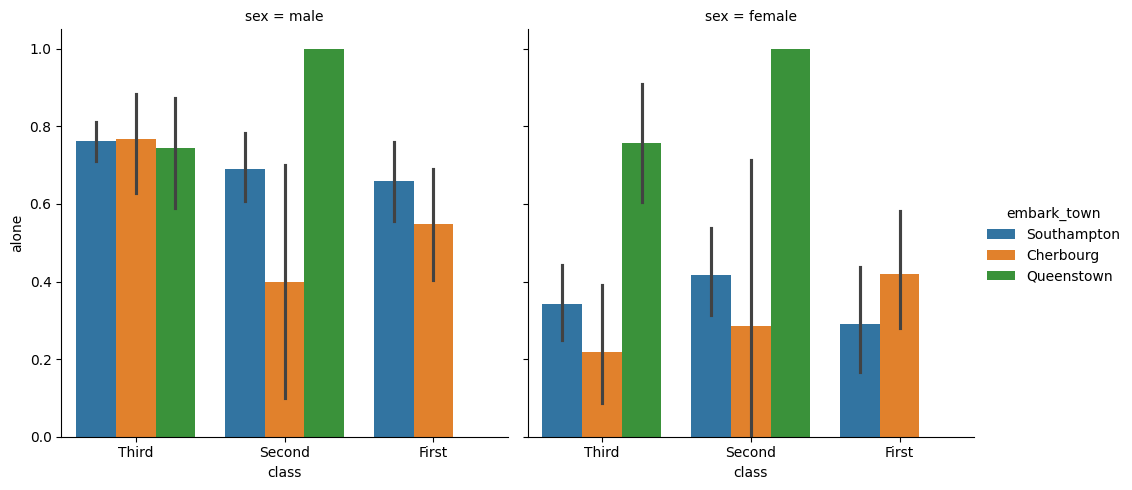

In [ ]:
sns.catplot(data=df, x='class', y='alone', order=class_order, hue='embark_town', col='sex', kind='bar');


## Converting Wide Tables into Tidy, Long Tables using `pd.melt()`

The `pd.melt()` function and `DataFrame.melt()` method take a single dataframe and make it **longer** by taking data stored in column names and putting it into the rows along with the rest of the data, adding extra metadata in the process.

For example, it can turn this `df` DataFrame:

| Month | Year | Monday | Tuesday | Wednesday |
| :--:  | :--: | :--:   | :--:    | :--:      |
| January | 2021 | 0 | -2 | -1 |
| February | 2021 | 2 | 4 | -2 |

into this:

| Month | Year | Weekday | Temperature |
| :--:  | :--: | :--:    |  :--:       |
| January | 2021 | Monday | 0 |
| January | 2021 | Tuesday | -2 |
| January | 2021 | Wednesday | -1 |
| February | 2021 | Monday | 2 |
| February | 2021 | Tuesday | 4 | 
| February | 2021 | Wednesday | -2 |

with one line of code:

```python
pd.melt(
    df, 
    id_vars=['Month', 'Year'],  # The columns that should stay the same
    value_vars=['Monday', 'Tuesday', 'Wednesday'],   # The columns that should melt
    var_name='Weekday',  # The new Column that will represent the melted column name's variable
    value_name='Temperature'  # The new Column that the data represents
)
```

**Note**: Melting a dataframe is also called *"tidying"* data, making a *"long"* dataframe from a *"wide"* dataframe, or building a *design matrix*.

| Code | Description |
|---|---|
| `pd.melt(df, id_vars=['col1'], value_vars=['col2', 'col3'])` | Melt a DataFrame by specifying which columns to keep (`id_vars`) and which to melt (`value_vars`). |
| `pd.melt(df, id_vars=['col1'], var_name='variable', value_name='value')` | Melt a DataFrame and specify custom names for the resulting variable and value columns. |
| `df.reset_index(drop=True)` | Reset the DataFrame index to 0, 1, 2, ... and drop the old index. |

Let's practice tidying dataframes with the `pd.melt()` function. Run the cell below to create a dataframe `df` containing data from the world bank dataset.

#### **Exercises**

In [37]:
df = (
    pd.read_csv('data/worldbankdata.csv')
    .get(['Country Name', 'Country Code', '1960', '1970', '1980', '1990', '2000'])
    .sample(10, random_state=42)
    .reset_index(drop=True)
)
df.head()

,Country Name,Country Code,1960,1970,1980,1990,2000
0,Peru,PER,6.876,6.307,5.009,3.828,2.929
1,Israel,ISR,3.866,3.778,3.242,2.824,2.950
2,"Congo, Dem. Rep.",COD,6.001,6.214,6.585,7.133,7.089
3,Zambia,ZMB,7.018,7.437,7.182,6.468,6.071
4,Benin,BEN,6.282,6.748,7.025,6.744,5.975


**Exercise**: Melt this dataset so it has four columns: "Country Name", "Country Code", "Year", and "Fertility Rate"

In [ ]:
df2 = pd.melt(df,
        id_vars = ['Country Name', 'Country Code'],
        value_vars = ['1960', '1970', '1980', '1990', '2000'],
        var_name='Decade',
        value_name='Birth Rate',
        )

In [ ]:
df2

,Country Name,Country Code,Decade,Birth Rate
0,Peru,PER,1960,6.876
1,Israel,ISR,1960,3.866
2,"Congo, Dem. Rep.",COD,1960,6.001
3,Zambia,ZMB,1960,7.018
4,Benin,BEN,1960,6.282
5,"Korea, Rep.",KOR,1960,6.155
6,Senegal,SEN,1960,6.951
7,"Venezuela, RB",VEN,1960,6.616
8,Greece,GRC,1960,2.277
9,New Caledonia,NCL,1960,6.278


## Joining Data with Different Columns Together

The `pd.merge()` function and `DataFrame.join()` method take two DataFrames and make them **wider** by matching rows with the same values on a specified column.  

For example, it can turn this `df1` DataFrame:

| Day | Weather |
| :-: | :---:   |
| Monday | Sunny   |
| Tuesday | Rainy |

and this `df2` DataFrame:

| Day | Temperature |
| :-: | :---:   |
| Tuesday | 12   |
| Monday | 18 |

into this:

| Day | Weather | Temperature |
| :-: | :---:   | :---: |
| Monday | Sunny   | 18 |
| Tuesday | Rainy | 12 |

with one line of code:

```python
df_merged = pd.merge(left=df1, right=df2, left_on="Day", right_on="Day")
```

Just specify which columns should be matched up with each other, and it will search for the matching values automatically!  If you want it to use the index, you can alternatively supply the option `left_index=True` and/or `right_index=True`. 

| Code | Description |
|---|---|
| `pd.merge(left=df1, right=df2, left_on='col1', right_on='col2')` | Merge two DataFrames based on matching column values. |
| `pd.merge(left=df1, right=df2, left_index=True, right_index=True)` | Merge two DataFrames using their indices. |
| `pd.merge(left=df1, right=df2, on='col', how='inner')` | Inner join: keep only rows that match in both DataFrames. |
| `pd.merge(left=df1, right=df2, on='col', how='outer')` | Outer join: keep all rows from both DataFrames, fill with NaN where no match. |
| `pd.merge(left=df1, right=df2, on='col', how='left')` | Left join: keep all rows from left DataFrame, fill with NaN where no match in right. |
| `pd.merge(left=df1, right=df2, on='col', how='right')` | Right join: keep all rows from right DataFrame, fill with NaN where no match in left. |

Run the cells below to create three dataframes that we'll use to practice merging with `pd.merge()`.

#### **Exercises**

In [ ]:
df1 = pd.DataFrame({'Name': ['Paul', 'Arash', 'Jenny'], 'Age': [16, 19, 17]})
df1

,Name,Age
0,Paul,16
1,Arash,19
2,Jenny,17


Dataframe 2:

In [ ]:
df2 = pd.DataFrame({'Name': ['Arash', 'Paul', 'Sara'], 'Weight': [32, 15, 37]})
df2

,Name,Weight
0,Arash,32
1,Paul,15
2,Sara,37


Dataframe 3:

In [ ]:
df3 = pd.DataFrame({'Name': ['Amy', 'Paul', 'Sara'], 'Height': [170, 190, 143]})
df3

,Name,Height
0,Amy,170
1,Paul,190
2,Sara,143


**Exercise**: Merge the first two dataframes together.  Who do we know both the age and weight of?

In [ ]:
pd.merge(left = df1, right = df2, left_on = 'Name', right_on='Name')

,Name,Age,Weight
0,Paul,16,15
1,Arash,19,32


**Exercise**: Try merging all 3 by merging twice.  Who do we know everything about?

In [ ]:
df_merge1 = pd.merge(left = df1, right = df2, left_on = 'Name', right_on='Name')
df = pd.merge(left=df_merge1, right = df3, left_on = 'Name', right_on = 'Name')
df

,Name,Age,Weight,Height
0,Paul,16,15,190


**Exercise**: Note that the Names that weren't present in both dataframes dropped out of the final result.  If you'd like to keep them and have NaNs appear, you can change the `how` parameter in the `pd.merge()` function.  Let's try out a few options by merging dataframes 1 and 2. Use `how="outer"`.

In [ ]:
pd.merge(left = df1, right = df2, left_on = 'Name', right_on = 'Name', how = "outer")

,Name,Age,Weight
0,Arash,19.0,32.0
1,Jenny,17.0,NaN
2,Paul,16.0,15.0
3,Sara,NaN,37.0


**Exercise**: Use `how="left"`.

In [ ]:
pd.merge(left = df1, right = df2, left_on = 'Name', right_on = 'Name', how = "left")

,Name,Age,Weight
0,Paul,16,15.0
1,Arash,19,32.0
2,Jenny,17,NaN


**Exercise**: Use `how="right"`.

In [ ]:
pd.merge(left = df1, right = df2, left_on = 'Name', right_on = 'Name', how = "right")

,Name,Age,Weight
0,Arash,19.0,32
1,Paul,16.0,15
2,Sara,NaN,37


**Exercise**: Use `how="inner"`.

In [ ]:
pd.merge(left = df1, right = df2, left_on = 'Name', right_on = 'Name', how = "inner")

,Name,Age,Weight
0,Paul,16,15
1,Arash,19,32
